# Variance reduction


The price was defined as the discounted expectation. With a Monte Carlo approach to the sampling, the standard error is

      std_err = sigma_payoff / sqrt(N)

Two levers follow, and no others.
- N: brute force approach, costly because of the square root: one more digit of
  accuracy needs a hundred times the samples.
- Lowering sigma_payoff: variance reduction techniques (investigated in this notebook).

A variance reduction technique must not change the price, only its spread. An
estimator that respects this requirement is called unbiased. Therefore every
technique is tested against a plain Monte Carlo run.

In [2]:
import numpy as np
import matplotlib.pyplot as plt

from mcpricer import analytical, estimators, models, payoffs

%matplotlib inline
plt.rcParams["figure.figsize"] = (7, 4)
plt.rcParams["figure.dpi"] = 110

S0, K, r, y, sigma, tau = 100.0, 100.0, 0.05, 0.0, 0.20, 1.0
rng = np.random.default_rng(42)

call = dict(payoff_fn=payoffs.call_payoff, model_fn=models.terminal_price,
            S0=S0, K=K, r=r, y=y, sigma=sigma, T=tau)

bs = analytical.black_scholes_call(S0, K, r, sigma, tau, y=y)
res = estimators.mc_price_european(N=1e6, rng=rng, **call)

print(f"Black-Scholes  {bs:.6f}")
print(f"plain MC       {res.price:.6f} +/- {res.std_err:.6f}")
print(f"deviation      {(res.price - bs) / res.std_err:+.2f} standard errors")
print(f"R              {res.rel_err:.5f}")
print(f"var_per_eval   {res.var_per_eval:.2f}")
print(f"fom            {res.fom:.3e}   ({res.elapsed * 1e3:.1f} ms)")

Black-Scholes  10.450584
plain MC       10.453195 +/- 0.014731
deviation      +0.18 standard errors
R              0.00141
var_per_eval   217.02
fom            4.867e+07   (10.3 ms)


           N      price   std_err     dev         R  var/eval   t [ms]
----------------------------------------------------------------------
       1,000   10.16160   0.44062  -0.66s   0.04336    194.14      0.3
      10,000   10.49095   0.14833  +0.27s   0.01414    220.02      0.4
     100,000   10.45896   0.04662  +0.18s   0.00446    217.38      1.7
   1,000,000   10.46001   0.01472  +0.64s   0.00141    216.67     12.8
  10,000,000   10.44721   0.00465  -0.73s   0.00045    216.53    108.2

fitted log-log slope  -0.4956   (theory -0.5)
var_per_eval          194.14 to 220.02


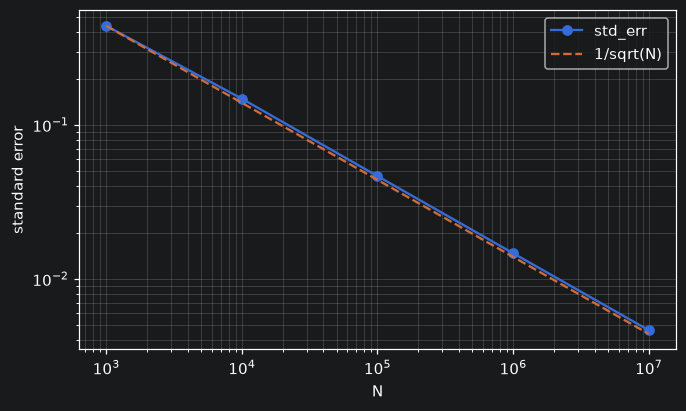

In [3]:
Ns = [10**k for k in range(3, 8)]
runs = [estimators.mc_price_european(N=N, rng=rng, **call) for N in Ns]

print(f"{"N":>12} {"price":>10} {"std_err":>9} {"dev":>7} {"R":>9} {"var/eval":>9} {"t [ms]":>8}")
print("-" * 70)
for run in runs:
    print(f"{run.n_samples:>12,} {run.price:>10.5f} {run.std_err:>9.5f} "
          f"{(run.price - bs) / run.std_err:>+6.2f}s {run.rel_err:>9.5f} "
          f"{run.var_per_eval:>9.2f} {run.elapsed * 1e3:>8.1f}")

errs = np.array([run.std_err for run in runs])

fig, ax = plt.subplots()
ax.loglog(Ns, errs, "o-", label="std_err")
ax.loglog(Ns, errs[0] * np.sqrt(Ns[0] / np.array(Ns, float)), "--", label="1/sqrt(N)")
ax.set_xlabel("N")
ax.set_ylabel("standard error")
ax.legend()
ax.grid(alpha=0.3, which="both")

print(f"\nfitted log-log slope  {np.polyfit(np.log(Ns), np.log(errs), 1)[0]:.4f}   (theory -0.5)")
print(f"var_per_eval          {min(q.var_per_eval for q in runs):.2f} to {max(q.var_per_eval for q in runs):.2f}")

## Comparison of the techniques

Two measures of cost are used.

var_per_eval rescales the variance to one payoff evaluation:

      var_per_eval = var * n_evals / n_samples

It is deterministic and the same on any machine.
The reduction factor of a technique is its var_per_eval against plain MC.

fom is the transport figure of merit, with relative error R = std_err / price:

      fom = 1 / (R^2 * t)

R^2 falls as 1/N while t grows as N, so the product is constant: the fom describes the
method, not the length of the run. It is the cost actually paid, but it is machine-specific and unreliable
at small N, where t is too short to measure. In Monte Carlo for radiation transport, usually one tries to maximize the FOM.
In practice, often a reduction of time increases R, and vice versa. Variance reduction is almost always paid for in time per
history, so the fom is the number that says whether the trade was worth it. This is why e.g.
splitting and Russian roulette are used together: one buys variance by spending time,
the other buys time by spending variance.

## Antithetic variates

Z and -Z have the same distribution, so every draw can be used twice for free. Instead
of N normals, draw N/2 and evaluate the payoff at both +Z and -Z, then average the pair.

The variance of a pair average is

      Var((X+ + X-)/2) = (1/2) * [Var(X) + Cov(X+, X-)]

so the gain comes from the covariance being negative.
That happens when the chain Z -> S_T -> payoff is monotone, which holds for
a call.
With positive covariance the pair would be noisier than two independent draws, so the
technique would lose against plain MC at the same budget.

One sample is now a pair and costs two payoff evaluations, so n_evals is 2 * len(Z)
while n_samples is len(Z). Due to this difference, variance per sample is not
comparable across estimators.

There is no direct counterpart in radiation transport Monte Carlo (MCNP, FLUKA); this is
correlated sampling, not biasing, with no involvement of any weights.

In [6]:
N = 1e6

plain = estimators.mc_price_european(N=N, rng=rng, **call)
anti = estimators.mc_antithetic(N=N, rng=rng, **call)

for name, q in (("plain", plain), ("antithetic", anti)):
    print(f"{name:11} price={q.price:.6f}  dev={(q.price - bs) / q.std_err:+5.2f}s  "
          f"se={q.std_err:.6f}  n_samples={q.n_samples:>9,}  n_evals={q.n_evals:>9,}")

print(f"\nvar per sample    {plain.var / anti.var:6.2f}x   <- not comparable")
print(f"var_per_eval      {plain.var_per_eval:7.2f} -> {anti.var_per_eval:7.2f}")
print(f"reduction factor  {plain.var_per_eval / anti.var_per_eval:6.2f}x   <- budget-fair")
print(f"fom               {plain.fom:.2e} -> {anti.fom:.2e}   ({anti.fom / plain.fom:.2f}x)")
print(f"time              {plain.elapsed * 1e3:.1f} ms -> {anti.elapsed * 1e3:.1f} ms")

plain       price=10.446170  dev=-0.30s  se=0.014719  n_samples=1,000,000  n_evals=1,000,000
antithetic  price=10.453565  dev=+0.29s  se=0.010400  n_samples=  500,000  n_evals=1,000,000

var per sample      4.01x   <- not comparable
var_per_eval       216.66 ->  108.17
reduction factor    2.00x   <- budget-fair
fom               3.28e+07 -> 1.12e+08   (3.41x)
time              15.4 ms -> 9.1 ms


In [7]:
# the mechanism: the two legs must be negatively correlated.
Z = rng.normal(size=500_000)
up = models.terminal_price(Z, r=r, T=tau, S0=S0, sigma=sigma, y=y)
down = models.terminal_price(-Z, r=r, T=tau, S0=S0, sigma=sigma, y=y)
corr = np.corrcoef(payoffs.call_payoff(up, K=K), payoffs.call_payoff(down, K=K))[0, 1]
print(f"corr(+Z, -Z)        {corr:+.4f}")
print(f"predicted var ratio {2 / (1 + corr):.2f}")

corr(+Z, -Z)        -0.5018
predicted var ratio 4.01
